# Phase 13 Part 1C — Frozen Best-Checkpoint Standalone GT-Free Proposal Analysis

**READ-ONLY REVIEWER NOTEBOOK.**

Performs: no training, no threshold search, no proposal grid, no regional
segmentation, no GLOBAL/ORACLE/PREDICTED comparison, no gate decision, no TEST access.

It reads the frozen Part-1C tables produced by the single authorized
best-checkpoint full-VAL inference pass.


## 2. Frozen checkpoint / protocol identity


In [1]:
import json, hashlib
from pathlib import Path
import pandas as pd, numpy as np
ROOT = Path(r'D:\Softfors\jup')
TABLES = ROOT / 'reports' / 'tables'
AUDITS = ROOT / 'reports' / 'audits'
EXP = 'phase13b_kub_localizer_r512_h128_sigmaeq075_centernetfocal_seed42_clean_v3'
def sha(p): return hashlib.sha256(Path(p).read_bytes()).hexdigest()
PROTO = json.loads((AUDITS / 'phase13_part1c_best_checkpoint_proposal_protocol.json').read_text(encoding='utf-8'))
AUDIT = json.loads((AUDITS / 'phase13_part1c_best_checkpoint_proposal_evaluation.json').read_text(encoding='utf-8'))
print('protocol status   :', PROTO['status'])
print('best epoch        :', PROTO['best_checkpoint_epoch'])
print('best.pt sha       :', PROTO['best_checkpoint_sha'])
print('physical best.pt  :', sha(ROOT / 'checkpoints' / EXP / 'best.pt'))
print('sha match         :', PROTO['best_checkpoint_sha'] == sha(ROOT / 'checkpoints' / EXP / 'best.pt'))
print('manifest/taxonomy :', PROTO['manifest'], '/', PROTO['taxonomy'])


protocol status   : SUPERVISOR_FROZEN_PART1C
best epoch        : 53
best.pt sha       : 7673c34a2f2c86eca2e45c1bc6abe77842d17cd09f122f2da0f2d414ca492273
physical best.pt  : 7673c34a2f2c86eca2e45c1bc6abe77842d17cd09f122f2da0f2d414ca492273
sha match         : True
manifest/taxonomy : phase4_v3 / kub_size_clean_v3_v1


## 3. Population integrity


In [2]:
case = pd.read_csv(TABLES / 'phase13_part1c_best_checkpoint_case_proposals.csv')
prop = pd.read_csv(TABLES / 'phase13_part1c_best_checkpoint_proposals.csv')
comp = pd.read_csv(TABLES / 'phase13_part1c_best_checkpoint_component_coverage.csv')
print('VAL cases      :', len(case), '(expected 103)')
print('VAL components :', len(comp), '(expected 152)')
print('strata         :', comp.size_stratum.value_counts().to_dict())
print('hard-Tiny      :', int(comp.hard_tiny.sum()), '(expected 15)')
print('global-empty   :', comp[comp.global_empty_image].sample_id.nunique(), '(expected 5)')
assert len(case) == 103 and len(comp) == 152
assert int(comp.hard_tiny.sum()) == 15
assert comp[comp.global_empty_image].sample_id.nunique() == 5


VAL cases      : 103 (expected 103)
VAL components : 152 (expected 152)
strata         : {'TINY': 72, 'MEDIUM': 36, 'SMALL': 28, 'LARGE': 16}
hard-Tiny      : 15 (expected 15)
global-empty   : 5 (expected 5)


## 4. Proposal generation contract


In [3]:
cfg = PROTO
print('threshold/margin/top_k/nms :', cfg['proposal_threshold'], cfg['proposal_margin'], cfg['proposal_top_k'], cfg['proposal_nms_iou'])
print('proposal configurations    :', cfg['proposal_configurations'])
print('grid search                :', cfg['grid_search'])
print('heatmap                    :', cfg['heatmap'])
print('GT used for proposal generation: NO (GT only after proposals exist)')
print('total proposals            :', len(prop), '(expected 494)')


threshold/margin/top_k/nms : 0.1 0.2 5 0.3
proposal configurations    : 1
grid search                : DISABLED
heatmap                    : {'input': 512, 'output': 128}
GT used for proposal generation: NO (GT only after proposals exist)
total proposals            : 494 (expected 494)


## 5. Bbox-vs-pixel semantics


In [4]:
print('PRIMARY   :', AUDIT['primary_coverage'])
print('SECONDARY :', AUDIT['secondary_sensitivity'])
print('pixel metrics are selection metrics:', False)


PRIMARY   : HISTORICAL_EXECUTING_BBOX_COVERAGE
SECONDARY : PIXEL_MASK_COMPONENT_COVERAGE
pixel metrics are selection metrics: False


## 6. Aggregate reproduction gate


In [5]:
rg = AUDIT['reproduction_gate']
print('status    :', rg['status'])
print('mismatches:', len(rg['mismatches']))
assert rg['status'] == 'PASS' and not rg['mismatches']
for k, v in sorted(rg['expected_bbox'].items()):
    print(f'  bbox  {k:32s} got={AUDIT["bbox_metrics"][k]!r} expected={v!r}')


status    : PASS
mismatches: 0
  bbox  any_overlap_recall               got=0.8486842105263158 expected=0.8486842105263158
  bbox  global_empty_images_covered90    got=1 expected=1
  bbox  hard_tiny_recovered90            got=4 expected=4
  bbox  mean_coverage                    got=0.7584022780771768 expected=0.7584022780771768
  bbox  mean_proposals_per_image         got=4.796116504854369 expected=4.796116504854369
  bbox  mean_roi_area_fraction           got=0.004846047236646118 expected=0.004846047236646169
  bbox  multi_component_recall90         got=0.5714285714285714 expected=0.5714285714285714
  bbox  overall_recall50                 got=0.7894736842105263 expected=0.7894736842105263
  bbox  overall_recall90                 got=0.5986842105263158 expected=0.5986842105263158
  bbox  tiny_recall90                    got=0.6805555555555556 expected=0.6805555555555556


## 7. Canonical aggregate localization metrics (BBOX — PRIMARY)


In [6]:
for k, v in AUDIT['bbox_metrics'].items(): print(f'{k:32s} {v!r}')


tiny_recall90                    0.6805555555555556
overall_recall90                 0.5986842105263158
mean_roi_area_fraction           0.004846047236646118
hard_tiny_recovered90            4
global_empty_images_covered90    1
multi_component_recall90         0.5714285714285714
mean_proposals_per_image         4.796116504854369
overall_recall50                 0.7894736842105263
any_overlap_recall               0.8486842105263158
mean_coverage                    0.7584022780771768


## 8. Pixel sensitivity metrics (SECONDARY)


In [7]:
for k, v in AUDIT['pixel_metrics'].items(): print(f'{k:32s} {v!r}')


tiny_recall90                    0.6944444444444444


overall_recall90                 0.6644736842105263
hard_tiny_recovered90            5
global_empty_images_covered90    1
multi_component_recall90         0.6224489795918368
overall_recall50                 0.8026315789473685
any_overlap_recall               0.8486842105263158
mean_coverage                    0.7768993431799454


## 9. Proposal-count / ROI-area distributions


In [8]:
FIG = ROOT / 'reports' / 'figures' / 'phase13_part1c'
FIG.mkdir(parents=True, exist_ok=True)
import matplotlib; matplotlib.use('Agg'); import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].hist(case['proposal_count'], bins=range(0, int(case['proposal_count'].max()) + 2), color='steelblue')
ax[0].set_xlabel('proposals per image'); ax[0].set_ylabel('images'); ax[0].set_title('Proposal count')
ax[1].hist(case['proposal_union_area_fraction'], bins=30, color='darkorange')
ax[1].set_xlabel('union ROI area fraction'); ax[1].set_title('ROI area')
for a in ax: a.grid(alpha=0.3)
fig.tight_layout(); fig.savefig(FIG / 'proposal_distributions.png', dpi=120); plt.close(fig)
print('mean proposals/image :', float(case['proposal_count'].mean()))
print('mean ROI area frac   :', float(case['proposal_union_area_fraction'].mean()))


mean proposals/image : 4.796116504854369
mean ROI area frac   : 0.004846047236646118


## 10. Size-stratified coverage


In [9]:
strat = pd.read_csv(TABLES / 'phase13_part1c_size_stratified_coverage.csv')
print(strat[['stratum','n_components','bbox_covered90_count','bbox_covered90_rate',
             'bbox_mean_coverage','pixel_covered90_count','pixel_covered90_rate']].to_string(index=False))


stratum  n_components  bbox_covered90_count  bbox_covered90_rate  bbox_mean_coverage  pixel_covered90_count  pixel_covered90_rate
   TINY            72                    49             0.680556            0.715587                     50              0.694444
  SMALL            28                    16             0.571429            0.826841                     20              0.714286
 MEDIUM            36                    19             0.527778            0.792796                     22              0.611111
  LARGE            16                     7             0.437500            0.753914                      9              0.562500
    ALL           152                    91             0.598684            0.758402                    101              0.664474


## 11. Hard-Tiny analysis


In [10]:
hard = comp[comp.hard_tiny]
print('hard-Tiny components:', len(hard))
print('bbox covered90 :', int(hard.bbox_covered90.sum()), '/', len(hard))
print('pixel covered90:', int(hard.pixel_covered90.sum()), '/', len(hard))


hard-Tiny components: 15
bbox covered90 : 4 / 15
pixel covered90: 5 / 15


## 12. Global-empty analysis


In [11]:
ge = comp[comp.global_empty_image]
print('global-empty images:', ge.sample_id.nunique())
print('bbox images covered90 :', len({r.sample_id for r in ge.itertuples() if r.bbox_covered90}), '/', ge.sample_id.nunique())
print('pixel images covered90:', len({r.sample_id for r in ge.itertuples() if r.pixel_covered90}), '/', ge.sample_id.nunique())


global-empty images: 5
bbox images covered90 : 1 / 5
pixel images covered90: 1 / 5


## 13. Multi-component analysis


In [12]:
multi_ids = set(comp.groupby('sample_id').size().loc[lambda v: v > 1].index)
multi = comp[comp.sample_id.isin(multi_ids)]
print('multi-component images:', len(multi_ids))
print('multi-component rows  :', len(multi))
print('bbox recall90 :', float(multi.bbox_covered90.mean()))
print('pixel recall90:', float(multi.pixel_covered90.mean()))


multi-component images: 49
multi-component rows  : 98
bbox recall90 : 0.5714285714285714
pixel recall90: 0.6224489795918368


## 14. Proposal any-hit precision (DESCRIPTIVE ONLY)


In [13]:
p = AUDIT['proposal_any_hit_precision']
print('proposal_bbox_any_hit_precision :', p['proposal_bbox_any_hit_precision'])
print('proposal_pixel_any_hit_precision:', p['proposal_pixel_any_hit_precision'])
print('role:', p['role'])


proposal_bbox_any_hit_precision : 0.24898785425101214
proposal_pixel_any_hit_precision: 0.24696356275303644
role: DESCRIPTIVE_ONLY_NOT_SELECTION_NOT_GATE_NOT_TUNED


## 15. Bbox-vs-pixel disagreement analysis


In [14]:
d = AUDIT['bbox_pixel_disagreement']
print('covered90 disagreements :', d['covered90_disagreements'])
print('covered50 disagreements :', d['covered50_disagreements'])
print('any-overlap disagreements:', d['any_overlap_disagreements'])
print('mean bbox - pixel       :', d['mean_bbox_minus_pixel'])
print('by stratum              :', d['by_stratum_mean'])


covered90 disagreements : 10
covered50 disagreements : 4
any-overlap disagreements: 0
mean bbox - pixel       : -0.01849706510276846
by stratum              : {'TINY': -0.004707144266427323, 'SMALL': -0.024798879421307835, 'MEDIUM': -0.03584090539544789, 'LARGE': -0.03049989315033095}


## 16. Uncovered-component inventory


In [15]:
unc = pd.read_csv(TABLES / 'phase13_part1c_uncovered_components.csv')
print('uncovered (bbox_covered90 == False):', len(unc), '/', len(comp))
print(unc.size_stratum.value_counts().to_dict())
print(unc.head(15).to_string(index=False))


uncovered (bbox_covered90 == False): 61 / 152
{'TINY': 23, 'MEDIUM': 17, 'SMALL': 12, 'LARGE': 9}
                       sample_id  component_id size_stratum  hard_tiny  global_empty_image  bbox_coverage_fraction  pixel_coverage_fraction  proposal_count  max_proposal_score  component_ratio
1ba084b5439ffee651b4f5e0697e2209             1         TINY      False               False                0.000000                 0.000000               5            0.125065         0.000069
64fa38b86930065b413e12b8c8308745             1         TINY      False               False                0.805556                 0.881523               5            0.125065         0.000075
8959dfc29ab5e06d0b2a0f41a4729dde             2         TINY      False               False                0.000000                 0.000000               5            0.125065         0.000094
3a60721211529da5e0672ceedace34e1             1         TINY      False               False                0.000000                

## 17. Historical v2 provenance-only context


In [16]:
ctx = pd.read_csv(TABLES / 'phase13_part1c_historical_context.csv')
print(ctx.to_string(index=False))
print()
print('LABEL:', ctx['comparison_label'].iloc[0])
print('No improvement/regression/significance/paired-delta claim is made.')


          population  val_images  val_components  tiny  tiny_recall90  overall_recall90 hard_tiny global_empty  mean_roi_area_fraction  mean_proposals_per_image                                  comparison_label
historical_phase4_v2         106             156    73       0.726027          0.641026    7 / 16        3 / 7                0.005899                  4.660377 DIFFERENT_POPULATIONS_DESCRIPTIVE_PROVENANCE_ONLY
     clean_v3_part1c         103             152    72       0.680556          0.598684    4 / 15        1 / 5                0.004846                  4.796117 DIFFERENT_POPULATIONS_DESCRIPTIVE_PROVENANCE_ONLY

LABEL: DIFFERENT_POPULATIONS_DESCRIPTIVE_PROVENANCE_ONLY
No improvement/regression/significance/paired-delta claim is made.


## 18. 16-case deterministic proposal gallery

Selection is SHA256(sample_id)-ordered, fixed **before** any outcome was read.
Label: `DETERMINISTIC_PREDICTION_INDEPENDENT_GALLERY_ONLY`.

**GT USED FOR REVIEW / EVALUATION ONLY — NOT FOR PROPOSAL GENERATION.**


In [17]:
gallery = pd.read_csv(TABLES / 'phase13_part1c_gallery_selection.csv')
print('gallery cases:', len(gallery), '/ 16')
print(gallery.to_string(index=False))
assert len(gallery) == 16


gallery cases:

 16 / 16
 selection_rank                        sample_id                                                 sha256_sample_id                                             label
              1 e6db42e46d012311069580771d4bec32 00460fed8885f2ee09f33eb29d955cf76f69db0e939a7e9e7de81e228212721e DETERMINISTIC_PREDICTION_INDEPENDENT_GALLERY_ONLY
              2 938beef9b225180b072bb03cb80a1415 09dc88f718864bf781314bfec698ad1897d2ea1760d7b8a469b1031e6e5d95c7 DETERMINISTIC_PREDICTION_INDEPENDENT_GALLERY_ONLY
              3 501570377c27ca3a1b04f8e78ebbaa45 0b9bc97b046c85418e9a31abe09b6916d9ae430e6f6db051201e6b75df519216 DETERMINISTIC_PREDICTION_INDEPENDENT_GALLERY_ONLY
              4 6f1a73eb1dc3ddb7af81e8a2893a2e76 0c8c198f3a5f956b1c5e6d0cc0d3449cc0ad00b0d7b747ba42970e06d3441e36 DETERMINISTIC_PREDICTION_INDEPENDENT_GALLERY_ONLY
              5 66b947d8ead11ae1260bc3142ca1707d 0c9284c277704d6cea19ce63c0631a3216f4cd261108f23068812e481a77ecb6 DETERMINISTIC_PREDICTION_INDEPENDENT_GALLERY_ONLY
       

## 19. Limitations


- Proposal precision metrics are **descriptive only** (no IoU acceptance threshold).
- Pixel-mask coverage is **secondary sensitivity**, never a selection metric.
- The v2/v3 historical comparison spans **different populations**; no delta is claimed.
- Exactly **one** authorized inference pass was performed; no tuning followed.
- The gallery is prediction-independent and does not influence any metric.


## 20. Explicit stop boundary

**STOP.** No regional segmentation, no GLOBAL/ORACLE/PREDICTED comparison,
no gate decision (`NOT_DECIDED`), no Phase 14. TEST not read.


In [18]:
print('regional segmentation :', AUDIT['regional_segmentation'])
print('gate decision         :', AUDIT['gate_decision'])
print('training              :', AUDIT['training'])
print('optimizer             :', AUDIT['optimizer'])
print('grid configs          :', AUDIT['grid_configs'])
print('TEST reads            :', AUDIT['test_reads'])
print('next_action = WAIT_FOR_SUPERVISOR_PHASE13_PART1D_PREDICTED_REGION_SEGMENTATION_AUTHORIZATION')


regional segmentation :

 0
gate decision         : NOT_DECIDED
training              : 0
optimizer             : 0
grid configs          : 0
TEST reads            : 0
next_action = WAIT_FOR_SUPERVISOR_PHASE13_PART1D_PREDICTED_REGION_SEGMENTATION_AUTHORIZATION


## 21. Artifact SHA registry


In [19]:
reg = pd.read_csv(TABLES / 'phase13_part1b_training_artifact_registry.csv')
print('registry rows:', len(reg), '| missing:', int((reg['exists'] != True).sum()))
part1c = sorted(TABLES.glob('phase13_part1c_*.csv'))
for f in part1c:
    print(f'{sha(f)[:24]}  {f.name}')


registry rows:

 29 | missing: 0
d25c44ec1361365e261d3645  phase13_part1c_best_checkpoint_case_proposals.csv
2a3623fecbc1fc5dd5a2c2a1  phase13_part1c_best_checkpoint_component_coverage.csv
8c3151a3f1f9a56f0692c6ff  phase13_part1c_best_checkpoint_proposals.csv
1fcbc0ae93e1b63ef3b7c3f0  phase13_part1c_gallery_selection.csv
6b4371e9c5839e54a82ead7f  phase13_part1c_historical_context.csv
147d3947d53fce5102ad290d  phase13_part1c_size_stratified_coverage.csv
46cf8a5ade7e909d792d26a7  phase13_part1c_special_cohort_coverage.csv
f25372b2ff6b4e2257e9d1b9  phase13_part1c_uncovered_components.csv


## Descriptive Evaluation and Visual Evidence — Phase 13 (proposal / localizer)

**Metric source / provenance.** Central proposal-domain artifacts
(`project_evaluation_proposal_metrics_summary.csv`,
`project_evaluation_proposal_curves.json`) derived from the saved Phase-13B
per-proposal table, plus the saved size-stratified coverage table.

**Metric-domain label.** `LOCALIZATION_PROPOSAL_SUPPLY` +
`OBJECT_COMPONENT_DETECTION`. Added values are
`DESCRIPTIVE_SUPPORTING_METRIC__NOT_PROSPECTIVE_GATE`.

**No TN-based confusion matrix.** A proposal detector has no defensible
"true-negative" unit (background is unbounded), so a confusion matrix is
deliberately **not** produced here. Proposal quality is expressed as TP/FP
proposals, precision, FP/image, component recall and PR/FROC curves.

**Frozen operating point.** The PR/FROC curves are **descriptive**; the frozen
threshold is annotated only and is never re-selected from these curves.

**What this section does NOT prove.** These are single-seed descriptive VAL curves
for the frozen localizer; they are not a re-tuning of the operating point.

,artifact,sha256
0,project_evaluation_proposal_metrics_summary.csv,374d8afd1268f6cf
1,project_evaluation_proposal_curves.json,5123c48d9e5daa10
2,phase13_part1c_size_stratified_coverage.csv,147d3947d53fce51


,arm,metric_domain,images,total_proposals,proposals_per_image,tp_proposals,fp_proposals,proposal_precision,background_fraction,average_precision,pr_auc_available,froc_available,proposal_iou_mean,source,caveat
0,PHASE13B_LOCALIZER,LOCALIZATION_PROPOSAL_SUPPLY,103,494.0,4.796117,122.0,372,0.246964,0.753036,0.27539148220711346,True,True,NaN,DERIVED_FROM_SAVED_ARTIFACTS,proposal_score is heavily quantized in the per...
2,PHASE13B_PROPOSAL_PER_IMAGE,LOCALIZATION_PROPOSAL_SUPPLY,106,165.0,1.556604,NaN,36,NaN,NaN,NaN,False,False,NaN,DERIVED_FROM_SAVED_ARTIFACTS,NaN


,stratum,n_components,pixel_any_overlap_count,pixel_any_overlap_rate,pixel_covered90_count,pixel_covered90_rate
0,TINY,72,54,0.750000,50,0.694444
1,SMALL,28,26,0.928571,20,0.714286
2,MEDIUM,36,34,0.944444,22,0.611111
3,LARGE,16,15,0.937500,9,0.562500
4,ALL,152,129,0.848684,101,0.664474


C:\Users\user\AppData\Local\Temp\ipykernel_41772\1605825495.py:59: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  _plt.savefig(str(_p), dpi=150, bbox_inches='tight'); _plt.show(); _show(_p)


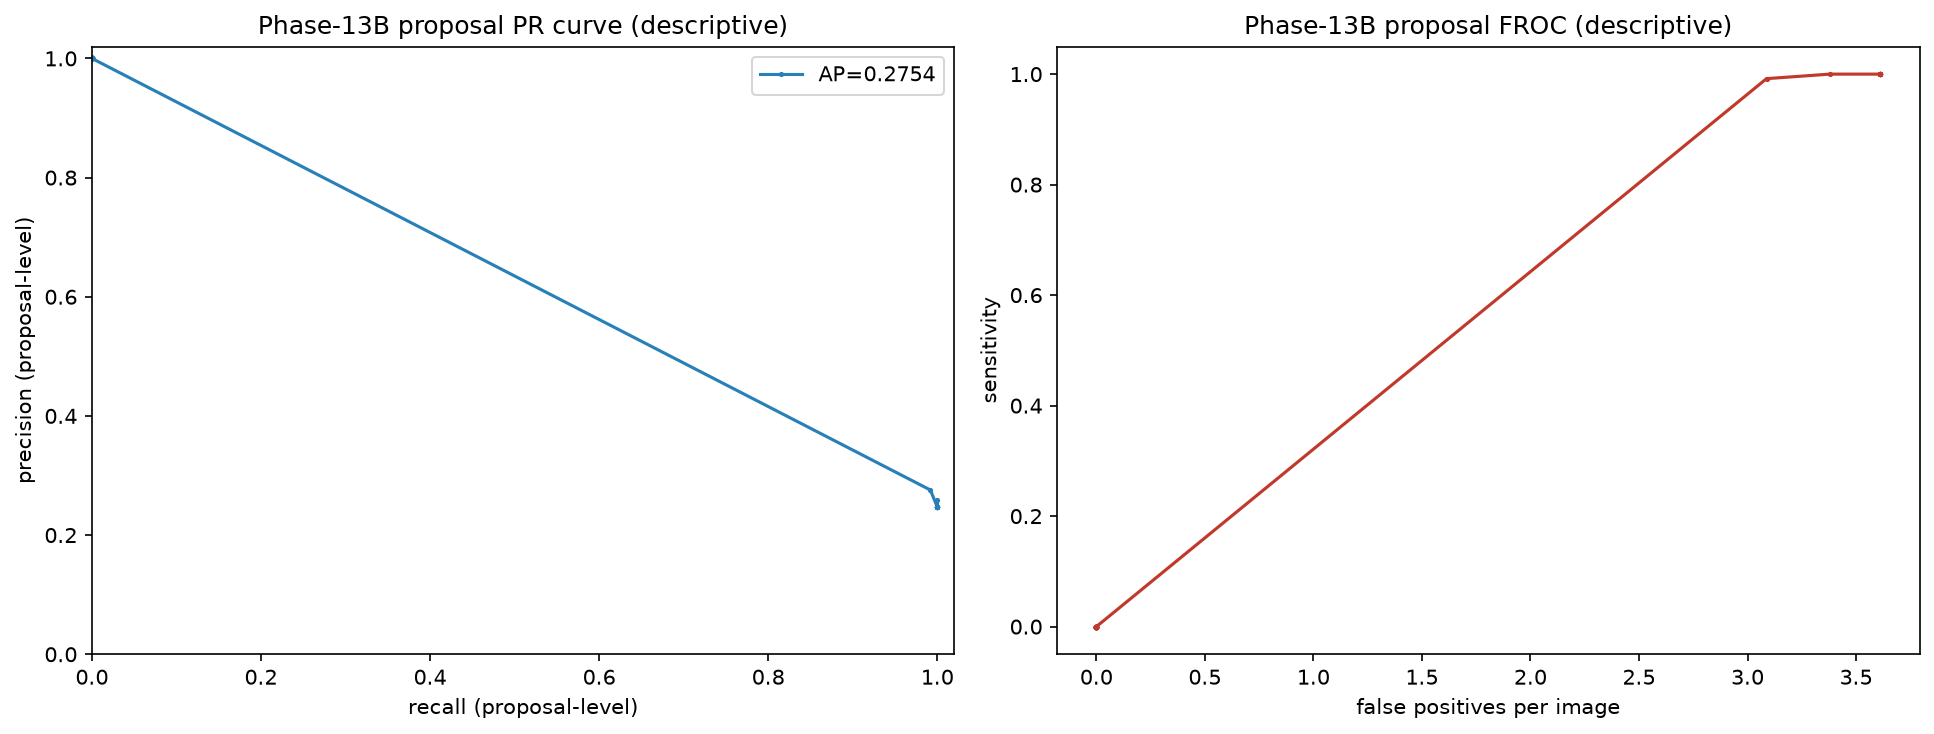

H3_PROPOSAL_SUPPLY: PR/FROC NOT MEANINGFUL -> best_proposal_score uses a -1.0 sentinel for components without an overlapping proposal; the score is therefore perfectly separable by construction and any PR/FROC curve over it is degenerate. Recorded as NOT_DERIVABLE_MEANINGFULLY.
Frozen operating threshold (annotated, not re-selected): 0.1
All values above are DESCRIPTIVE_SUPPORTING_METRIC__NOT_PROSPECTIVE_GATE


In [20]:
# ── Phasewise evaluation / visualization synchronization (post-audit) ─────────
import json as _json, hashlib as _hashlib
from pathlib import Path as _Path
import numpy as _np
import pandas as _pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as _plt
try:
    from IPython.display import display as _disp, Image as _Img
except Exception:
    _disp = print; _Img = None
_ROOT = _Path('D:/Softfors/jup')
_AUD = _ROOT / 'reports' / 'audits'
_TAB = _ROOT / 'reports' / 'tables'
_FIG = _ROOT / 'reports' / 'figures' / 'phasewise_sync'
_FIG.mkdir(parents=True, exist_ok=True)
def _sha(p): return _hashlib.sha256(_Path(p).read_bytes()).hexdigest()
def _load(p): return _json.loads(_Path(p).read_text(encoding='utf-8'))
def _show(p, w=840):
    if _Img is not None and _Path(p).exists():
        _disp(_Img(filename=str(p), width=w))
LBL      = 'DESCRIPTIVE_SUPPORTING_METRIC__NOT_PROSPECTIVE_GATE'
LBL_H3   = 'DESCRIPTIVE_SUPPORTING_METRIC__NOT_H3_GATE'
LBL_STAT = 'DESCRIPTIVE_POST_HOC_STATISTICAL_SUPPORT'

prov = [
    ('project_evaluation_proposal_metrics_summary.csv', _TAB / 'project_evaluation_proposal_metrics_summary.csv'),
    ('project_evaluation_proposal_curves.json', _TAB / 'project_evaluation_proposal_curves.json'),
    ('phase13_part1c_size_stratified_coverage.csv', _TAB / 'phase13_part1c_size_stratified_coverage.csv'),
]
_disp(_pd.DataFrame([{'artifact': n, 'sha256': _sha(p)[:16]} for n, p in prov if p.exists()]))

psum = _pd.read_csv(_TAB / 'project_evaluation_proposal_metrics_summary.csv')
_disp(psum[psum['arm'].str.contains('PHASE13B')])

cov = _pd.read_csv(_TAB / 'phase13_part1c_size_stratified_coverage.csv')
_disp(cov[['stratum', 'n_components', 'pixel_any_overlap_count', 'pixel_any_overlap_rate',
           'pixel_covered90_count', 'pixel_covered90_rate']])

curves = _load(_TAB / 'project_evaluation_proposal_curves.json')
p13 = curves.get('PHASE13B_LOCALIZER', {})
if p13.get('pr_curve'):
    pc = p13['pr_curve']
    order = _np.argsort(pc['recall'])
    rec = _np.array(pc['recall'])[order]; prec = _np.array(pc['precision'])[order]
    fig, (ax1, ax2) = _plt.subplots(1, 2, figsize=(13, 5))
    ax1.plot(rec, prec, marker='.', ms=3, color='#2980b9',
             label=f"AP={p13['average_precision_descriptive']:.4f}")
    ax1.set_xlabel('recall (proposal-level)'); ax1.set_ylabel('precision (proposal-level)')
    ax1.set_xlim(0, 1.02); ax1.set_ylim(0, 1.02)
    ax1.set_title('Phase-13B proposal PR curve (descriptive)'); ax1.legend()
    fr = p13.get('froc_curve')
    if fr:
        ax2.plot(fr['fp_per_image'], fr['sensitivity'], marker='.', ms=3, color='#c0392b')
        ax2.set_xlabel('false positives per image'); ax2.set_ylabel('sensitivity')
        ax2.set_title('Phase-13B proposal FROC (descriptive)')
    _plt.tight_layout(); _p = _FIG / 'phase13_pr_froc.png'
    _plt.savefig(str(_p), dpi=150, bbox_inches='tight'); _plt.show(); _show(_p)
else:
    print('PR curve unavailable for PHASE13B_LOCALIZER.')

for arm, d in curves.items():
    if d.get('pr_curve_meaningful') is False:
        print(f'{arm}: PR/FROC NOT MEANINGFUL -> {d.get("pr_curve_not_meaningful_reason")}')
print('Frozen operating threshold (annotated, not re-selected):', p13.get('operating_point_threshold'))
print('All values above are', LBL)